# Meilenstein 2 – Klassische Cartoon-Pipeline

Dieses Notebook dokumentiert das klassische Vergleichsverfahren aus Meilenstein 1
(neben GAN und Mehrfach-Adapter-Diffusion) mit allen Zwischenschritten:

1. **Bilateralfilter** – glättet Flächen, erhält aber Kanten.
2. **k-Means-Farbquantisierung** – reduziert die Farbpalette auf wenige Cluster
   und erzeugt den typischen "flachen" Cartoon-Farblook.
3. **Kantenerkennung** – extrahiert schwarze Konturlinien, die über das
   farbquantisierte Bild gelegt werden.

Alle drei Schritte lassen sich über **Intensitätsstufen** (1 = leicht, 2 = mittel,
3 = stark) und **Stile** (`soft`, `klassisch`, `poster`) parametrisieren – damit ist
die Anforderung "Parameter als Intensitätsstufen, mindestens 2 bis 3 Stile" erfüllt.

Als Eingabe dient durchgehend ein einziges echtes Foto (keine synthetischen
Platzhalterbilder), damit alle Beobachtungen für echte Fotos gelten.

> Hinweis: Dieses Notebook ist bewusst von der FastAPI-App (`backend/`) getrennt.
> Es dient der Recherche/Dokumentation für Meilenstein 2; die Integration der
> Pipeline in die App-Oberfläche (Regler, Verfahrensauswahl) folgt erst in
> Meilenstein 4.

In [14]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline
plt.rcParams["figure.facecolor"] = "white"


def show(images, titles, cmap=None, figsize=None):
    """Display a row of (BGR or grayscale) images side by side."""
    n = len(images)
    figsize = figsize or (4 * n, 4)
    fig, axes = plt.subplots(1, n, figsize=figsize)
    if n == 1:
        axes = [axes]
    for ax, img, title in zip(axes, images, titles):
        if img.ndim == 2:
            ax.imshow(img, cmap=cmap or "gray")
        else:
            ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        ax.set_title(title)
        ax.axis("off")
    fig.tight_layout()
    plt.show()

## Eingabebild

Ein echtes Foto (Tram 28 / Bica-Standseilbahn, Lissabon) mit natürlichem
Sensorrauschen, feinen Strukturen (Fassadendetails, Pflastersteine,
Fahrleitungen) und starkem Hell-Dunkel-Kontrast. Alle folgenden Schritte
arbeiten auf genau diesem Bild – für ein anderes Foto einfach die Datei unter
`samples/foto_tram.jpg` ersetzen oder den Pfad unten anpassen.

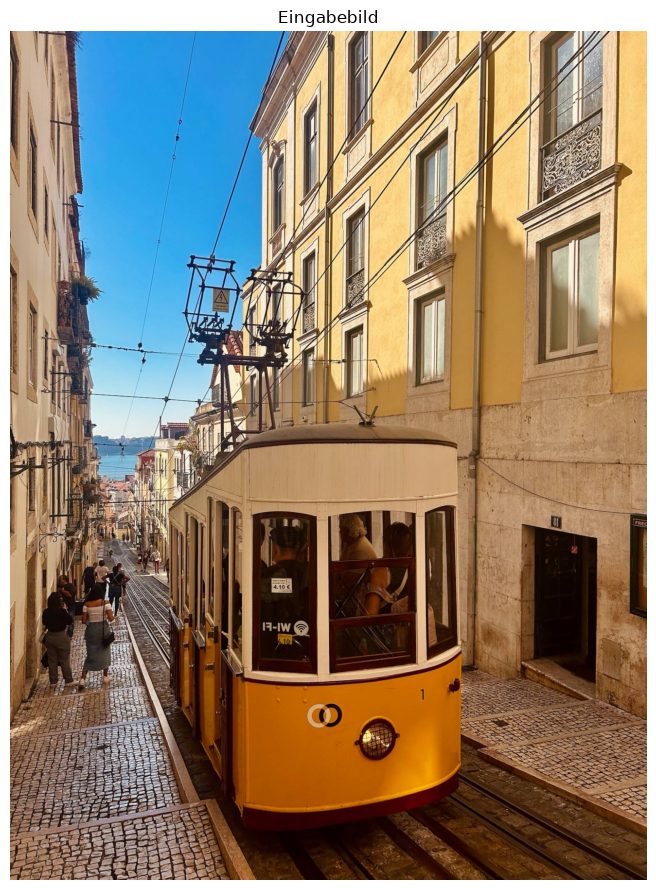

In [15]:
original = cv2.imread("samples/foto_tram.jpg")
if original is None:
    raise FileNotFoundError("samples/foto_tram.jpg nicht gefunden.")
show([original], ["Eingabebild"], figsize=(7, 9))

## Schritt 1: Bilateralfilter

**Methode:** `cv2.bilateralFilter(img, d, sigmaColor, sigmaSpace)`.

Anders als ein Gauß-Weichzeichner mittelt der Bilateralfilter einen Pixel nur
mit Nachbarn, die *räumlich nah* **und** *farblich ähnlich* sind. Dadurch
verschwindet Sensorrauschen und feine Textur, aber grobe Kanten (Hauskanten,
Fensterrahmen) bleiben erhalten, weil Pixel auf der anderen Seite einer Kante
farblich zu verschieden sind, um mit eingerechnet zu werden.

- **`d`** – Durchmesser der Nachbarschaft in Pixeln (wie weit räumlich geschaut wird).
- **`sigmaColor`** – wie groß ein Farbunterschied sein darf, damit zwei Pixel
  noch als "gleiche Fläche" gelten; größer = mehr Flächen werden zusammengelegt.
- **`sigmaSpace`** – wie stark der Einfluss mit der räumlichen Entfernung abfällt.
- **`iterations`** (eigener Parameter, kein cv2-Argument) – mehrfaches
  Anwenden verstärkt die Glättung, ohne dass einzelne Durchläufe ihre
  Kantenerhaltung verlieren.

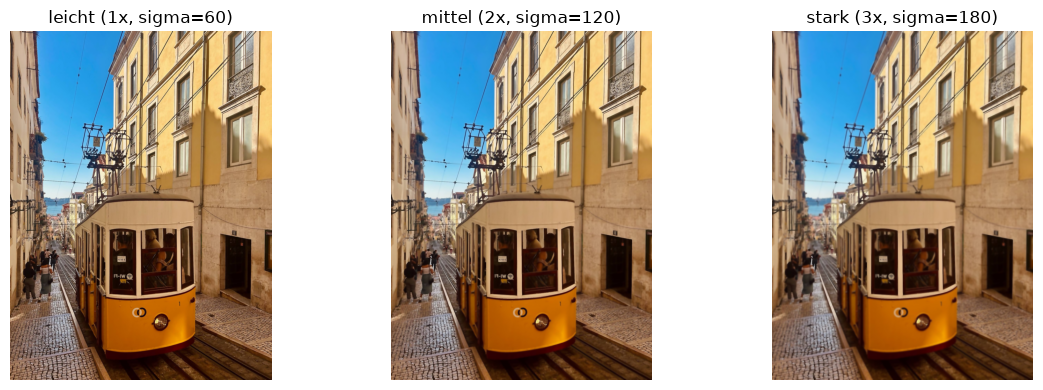

In [16]:
def apply_bilateral(img, d, sigma_color, sigma_space, iterations):
    result = img
    for _ in range(iterations):
        result = cv2.bilateralFilter(result, d, sigma_color, sigma_space)
    return result


bilateral_levels = {
    "leicht (1x, sigma=60)": apply_bilateral(original, 9, 60, 60, 1),
    "mittel (2x, sigma=120)": apply_bilateral(original, 9, 120, 120, 2),
    "stark (3x, sigma=180)": apply_bilateral(original, 9, 180, 180, 3),
}
show(list(bilateral_levels.values()), list(bilateral_levels.keys()))

## Schritt 2: k-Means-Farbquantisierung

**Methode:** `cv2.kmeans(data, k, ...)` auf die Pixel als Punkte im
3D-Farbraum (B, G, R).

1. Das Bild wird zu einer Liste von `(B, G, R)`-Punkten reshaped (`data`).
2. `cv2.kmeans` gruppiert diese Punkte in `k` Cluster und gibt für jeden
   Pixel einen Cluster-Index (`labels`) sowie die `k` Clusterzentren
   (`centers`, die tatsächlichen Quantisierungsfarben) zurück.
3. Jeder Pixel wird durch die Farbe seines Clusterzentrums ersetzt.

Parameter von `cv2.kmeans`:
- **`criteria`** (`TERM_CRITERIA_EPS + TERM_CRITERIA_MAX_ITER`, 20, 0.5) –
  bricht ab, sobald sich die Zentren kaum noch bewegen (< 0.5) oder nach
  spätestens 20 Iterationen.
- **`attempts=3`** – k-Means startet 3x mit unterschiedlicher Startposition
  der Zentren; das Ergebnis mit der geringsten Streuung wird behalten (k-Means
  kann in einem lokalen Minimum stecken bleiben, mehrere Versuche mindern das).
- **`flags=KMEANS_PP_CENTERS`** – nutzt k-means++ zur Startpositionierung
  (verteilt die Startzentren klug statt rein zufällig), das macht das Ergebnis
  stabiler.

Ein kleines `k` erzeugt wenige, kräftige Farbflächen (Poster-Look); ein großes
`k` erhält mehr Farbverläufe.

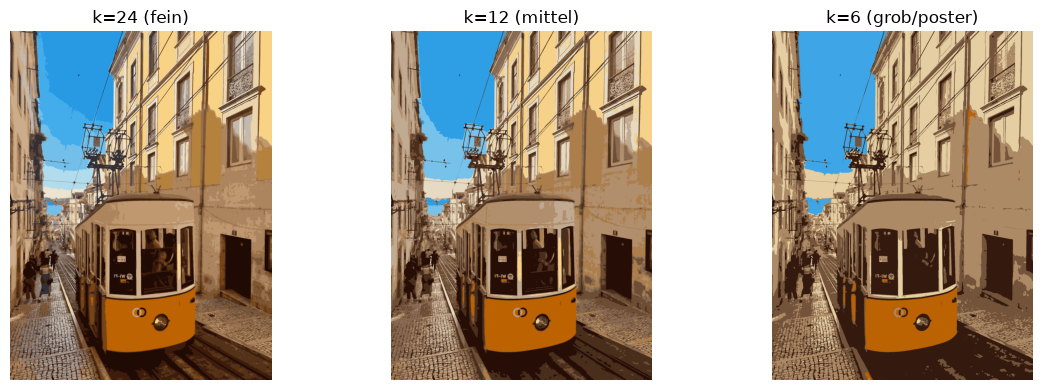

In [17]:
def quantize_colors(img, k):
    data = img.reshape((-1, 3)).astype(np.float32)
    criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 20, 0.5)
    _, labels, centers = cv2.kmeans(
        data, k, None, criteria, attempts=3, flags=cv2.KMEANS_PP_CENTERS
    )
    centers = np.uint8(centers)
    return centers[labels.flatten()].reshape(img.shape)


smoothed_for_quant = apply_bilateral(original, 9, 120, 120, 2)
quant_levels = {
    "k=24 (fein)": quantize_colors(smoothed_for_quant, 24),
    "k=12 (mittel)": quantize_colors(smoothed_for_quant, 12),
    "k=6 (grob/poster)": quantize_colors(smoothed_for_quant, 6),
}
show(list(quant_levels.values()), list(quant_levels.keys()))

## Schritt 3: Kantenerkennung

**Methoden:** `cv2.cvtColor` → `cv2.medianBlur` → `cv2.Canny` → `cv2.dilate`
→ `cv2.bitwise_not`.

1. **`cv2.cvtColor(img, COLOR_BGR2GRAY)`** – Kantenerkennung arbeitet auf
   Helligkeitsunterschieden, nicht auf Farbe, daher zuerst Graustufen.
2. **`cv2.medianBlur(gray, 7)`** – ersetzt jeden Pixel durch den *Median*
   seiner 7x7-Nachbarschaft statt den Mittelwert (wie bei Gauß). Das entfernt
   Restrauschen, ohne Kanten zu verschieben oder zu verwischen – wichtig, weil
   Canny sehr empfindlich auf Rauschen reagiert.
3. **`cv2.Canny(blurred, canny_low, canny_high)`** – berechnet zunächst den
   Helligkeitsgradienten (Sobel) und wendet dann **Hysterese-Schwellenwerte**
   an: Pixel mit Gradient über `canny_high` sind sichere Kanten; Pixel
   zwischen `canny_low` und `canny_high` zählen nur als Kante, wenn sie mit
   einer sicheren Kante verbunden sind; alles darunter wird verworfen. Niedrige
   Schwellen → mehr (auch falsche) Kanten; hohe Schwellen → nur starke Kanten,
   feine Konturen gehen verloren.
4. **`cv2.dilate(edges, kernel, iterations=1)`** – "fettet" die gefundenen
   Kantenlinien mit einem `thickness x thickness`-Kernel auf, für kräftigere
   Konturen (nur wenn `thickness > 1`).
5. **`cv2.bitwise_not(edges)`** – invertiert das Bild (schwarze Linien auf
   weißem Grund), damit es sich im nächsten Schritt per `bitwise_and` über
   das Farbbild legen lässt.

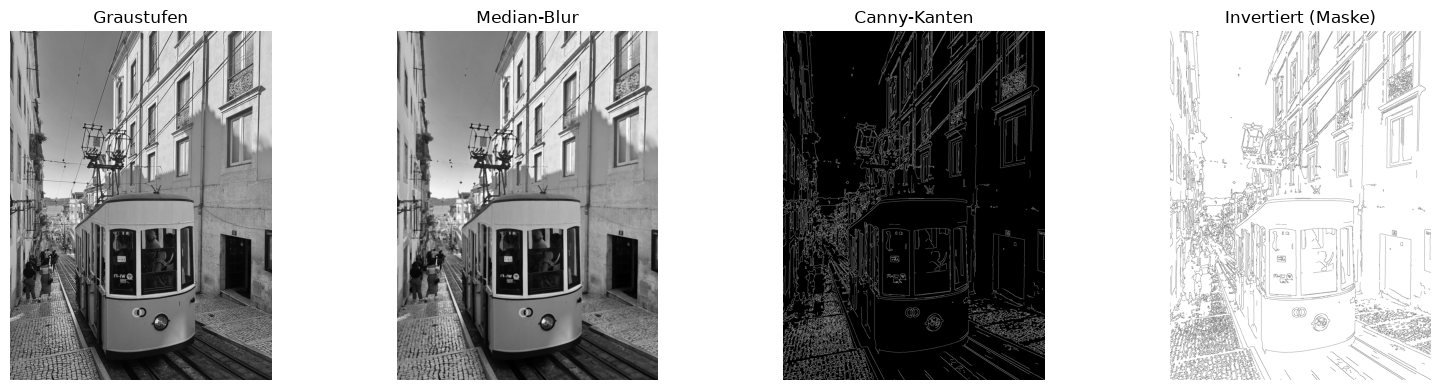

In [18]:
def detect_edges(img, canny_low, canny_high, thickness=1):
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    blurred = cv2.medianBlur(gray, 7)
    edges = cv2.Canny(blurred, canny_low, canny_high)
    if thickness > 1:
        kernel = np.ones((thickness, thickness), np.uint8)
        edges = cv2.dilate(edges, kernel, iterations=1)
    inverted = cv2.bitwise_not(edges)
    return gray, blurred, edges, inverted


gray, blurred, edges, inverted = detect_edges(original, 60, 140, thickness=1)
show(
    [gray, blurred, edges, inverted],
    ["Graustufen", "Median-Blur", "Canny-Kanten", "Invertiert (Maske)"],
)

## Gesamtpipeline

**Methode:** `cv2.bitwise_and(quantized, edge_mask_3ch)`.

Die drei Schritte werden kombiniert: Das farbquantisierte, geglättete Bild
wird mit der invertierten, auf 3 Kanäle kopierten Kantenmaske per
bitweisem UND verrechnet. An jeder Pixelposition gilt: Maske weiß (255) lässt
die Quantisierungsfarbe unverändert durch, Maske schwarz (0, = Kantenlinie)
setzt das Ergebnis auf Schwarz – so entstehen die charakteristischen
Cartoon-Konturen.

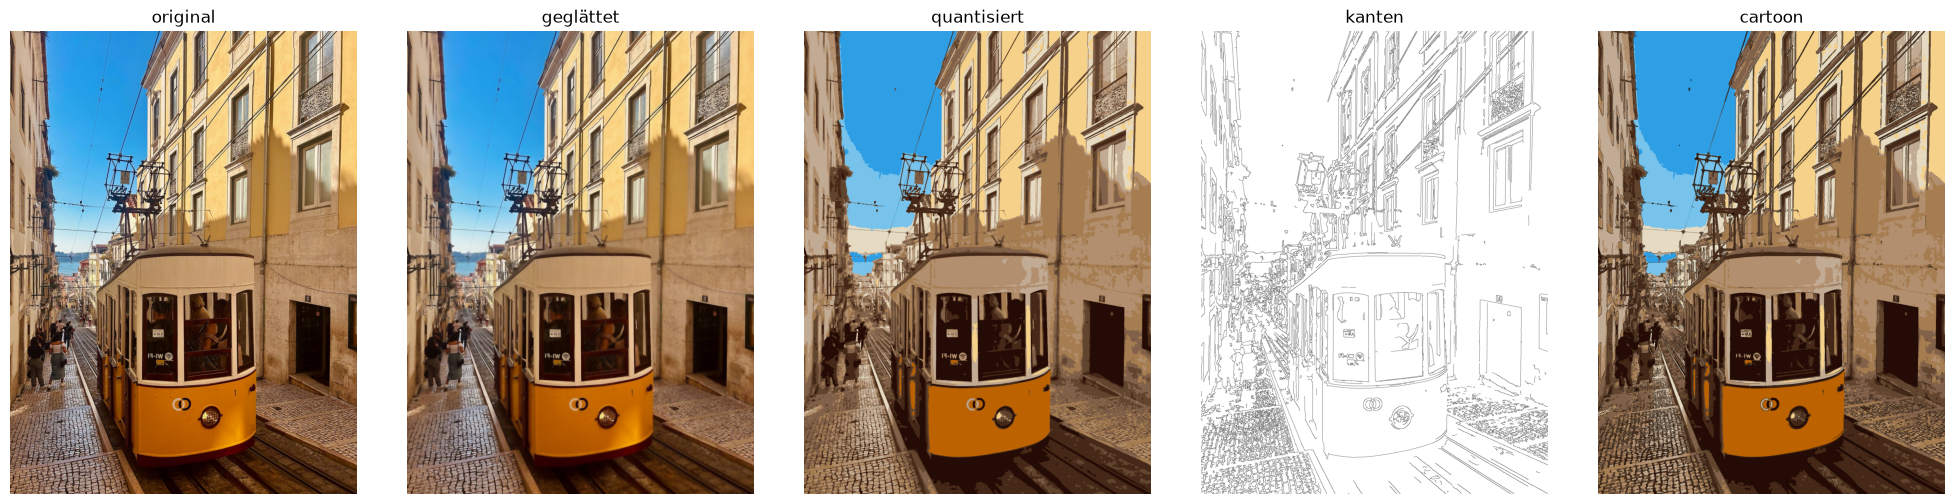

In [19]:
def cartoonify(img, bilateral, k_colors, canny_low, canny_high, edge_thickness, return_steps=False):
    smoothed = apply_bilateral(
        img, bilateral["d"], bilateral["sigma_color"], bilateral["sigma_space"], bilateral["iterations"]
    )
    quantized = quantize_colors(smoothed, k_colors)
    _, _, _, edge_mask = detect_edges(img, canny_low, canny_high, edge_thickness)
    edge_mask_3ch = cv2.cvtColor(edge_mask, cv2.COLOR_GRAY2BGR)
    cartoon = cv2.bitwise_and(quantized, edge_mask_3ch)
    if return_steps:
        return cartoon, {
            "original": img,
            "geglättet": smoothed,
            "quantisiert": quantized,
            "kanten": edge_mask,
            "cartoon": cartoon,
        }
    return cartoon


_, steps = cartoonify(
    original,
    bilateral=dict(d=9, sigma_color=120, sigma_space=120, iterations=2),
    k_colors=12,
    canny_low=60,
    canny_high=140,
    edge_thickness=1,
    return_steps=True,
)
show(list(steps.values()), list(steps.keys()), figsize=(20, 5))

## Stile und Intensitätsstufen

Drei Stile bündeln sinnvolle Parameterkombinationen (welche Methode mit
welcher Stärke eingesetzt wird); jede Intensitätsstufe (1 = leicht, 2 =
mittel, 3 = stark) skaliert diese Basiswerte über Multiplikatoren:

| Stil | Idee | Bilateralfilter (`d`,`sigmaColor`/`sigmaSpace`,Iterationen) | k-Means (`k`) | Kantenerkennung (Canny-Schwellen, Dicke) |
|---|---|---|---|---|
| `soft` | sanfter, gemalter Look | 9, 75, 2x | 20 (viele Farben, weiche Verläufe) | 40/90, dünn |
| `klassisch` | typischer Comic-Look | 9, 120, 2x | 12 (mittlere Clusteranzahl) | 60/140, mittel |
| `poster` | grafisches Poster | 7, 200, 1x | 6 (wenige, kräftige Flächen) | 80/160, dick |

Die Intensitätsstufe skaliert pro Stil:
- **`bilateral_mult`** – multipliziert `sigmaColor`/`sigmaSpace` *und* die
  Anzahl der Filterdurchläufe (stärkere Glättung bei höherer Intensität).
- **`k_mult`** – multipliziert die Clusteranzahl `k`; **invers** zur
  Intensität (Stufe 1 = mehr Cluster = näher am Foto, Stufe 3 = weniger
  Cluster = stärker stilisiert).
- **`edge_mult`** – multipliziert die Kantendicke (`edge_thickness`).

In [20]:
STYLES = {
    "soft": dict(d=9, sigma_color=75, sigma_space=75, iterations=2, k_colors=20, canny_low=40, canny_high=90, edge_thickness=1),
    "klassisch": dict(d=9, sigma_color=120, sigma_space=120, iterations=2, k_colors=12, canny_low=60, canny_high=140, edge_thickness=1),
    "poster": dict(d=7, sigma_color=200, sigma_space=200, iterations=1, k_colors=6, canny_low=80, canny_high=160, edge_thickness=2),
}

# Faktoren, mit denen jede Intensitaetsstufe die Basiswerte eines Stils skaliert.
INTENSITY_SCALE = {
    1: dict(bilateral_mult=0.6, k_mult=1.4, edge_mult=0.7),  # leicht
    2: dict(bilateral_mult=1.0, k_mult=1.0, edge_mult=1.0),  # mittel = Basiswerte
    3: dict(bilateral_mult=1.6, k_mult=0.65, edge_mult=1.5),  # stark
}


def resolve_params(style, intensity):
    base = STYLES[style]
    scale = INTENSITY_SCALE[intensity]
    return dict(
        bilateral=dict(
            d=base["d"],
            sigma_color=round(base["sigma_color"] * scale["bilateral_mult"]),
            sigma_space=round(base["sigma_space"] * scale["bilateral_mult"]),
            iterations=max(1, round(base["iterations"] * scale["bilateral_mult"])),
        ),
        k_colors=max(3, round(base["k_colors"] * scale["k_mult"])),
        canny_low=base["canny_low"],
        canny_high=base["canny_high"],
        edge_thickness=max(1, round(base["edge_thickness"] * scale["edge_mult"])),
    )


def cartoonify_style(img, style, intensity, return_steps=False):
    params = resolve_params(style, intensity)
    return cartoonify(
        img,
        bilateral=params["bilateral"],
        k_colors=params["k_colors"],
        canny_low=params["canny_low"],
        canny_high=params["canny_high"],
        edge_thickness=params["edge_thickness"],
        return_steps=return_steps,
    )

### Konkrete Parameter je Stil und Intensitätsstufe

Damit die Multiplikatoren nicht abstrakt bleiben, hier die tatsächlich
verwendeten Zahlenwerte für alle 9 Kombinationen:

In [21]:
header = f"{'Stil':<10} {'Stufe':<6} {'sigmaColor/Space':<17} {'Iter.':<6} {'k (Farben)':<11} {'Kantendicke':<12}"
print(header)
print("-" * len(header))
for style in STYLES:
    for intensity in (1, 2, 3):
        p = resolve_params(style, intensity)
        print(
            f"{style:<10} {intensity:<6} {p['bilateral']['sigma_color']:<17} "
            f"{p['bilateral']['iterations']:<6} {p['k_colors']:<11} {p['edge_thickness']:<12}"
        )

Stil       Stufe  sigmaColor/Space  Iter.  k (Farben)  Kantendicke 
-------------------------------------------------------------------
soft       1      45                1      28          1           
soft       2      75                2      20          1           
soft       3      120               3      13          2           
klassisch  1      72                1      17          1           
klassisch  2      120               2      12          1           
klassisch  3      192               3      8           2           
poster     1      120               1      8           1           
poster     2      200               1      6           2           
poster     3      320               2      4           3           


### Vergleich: alle Stile x alle Intensitätsstufen

3 Stile × 3 Intensitätsstufen = 9 Varianten auf demselben Foto.

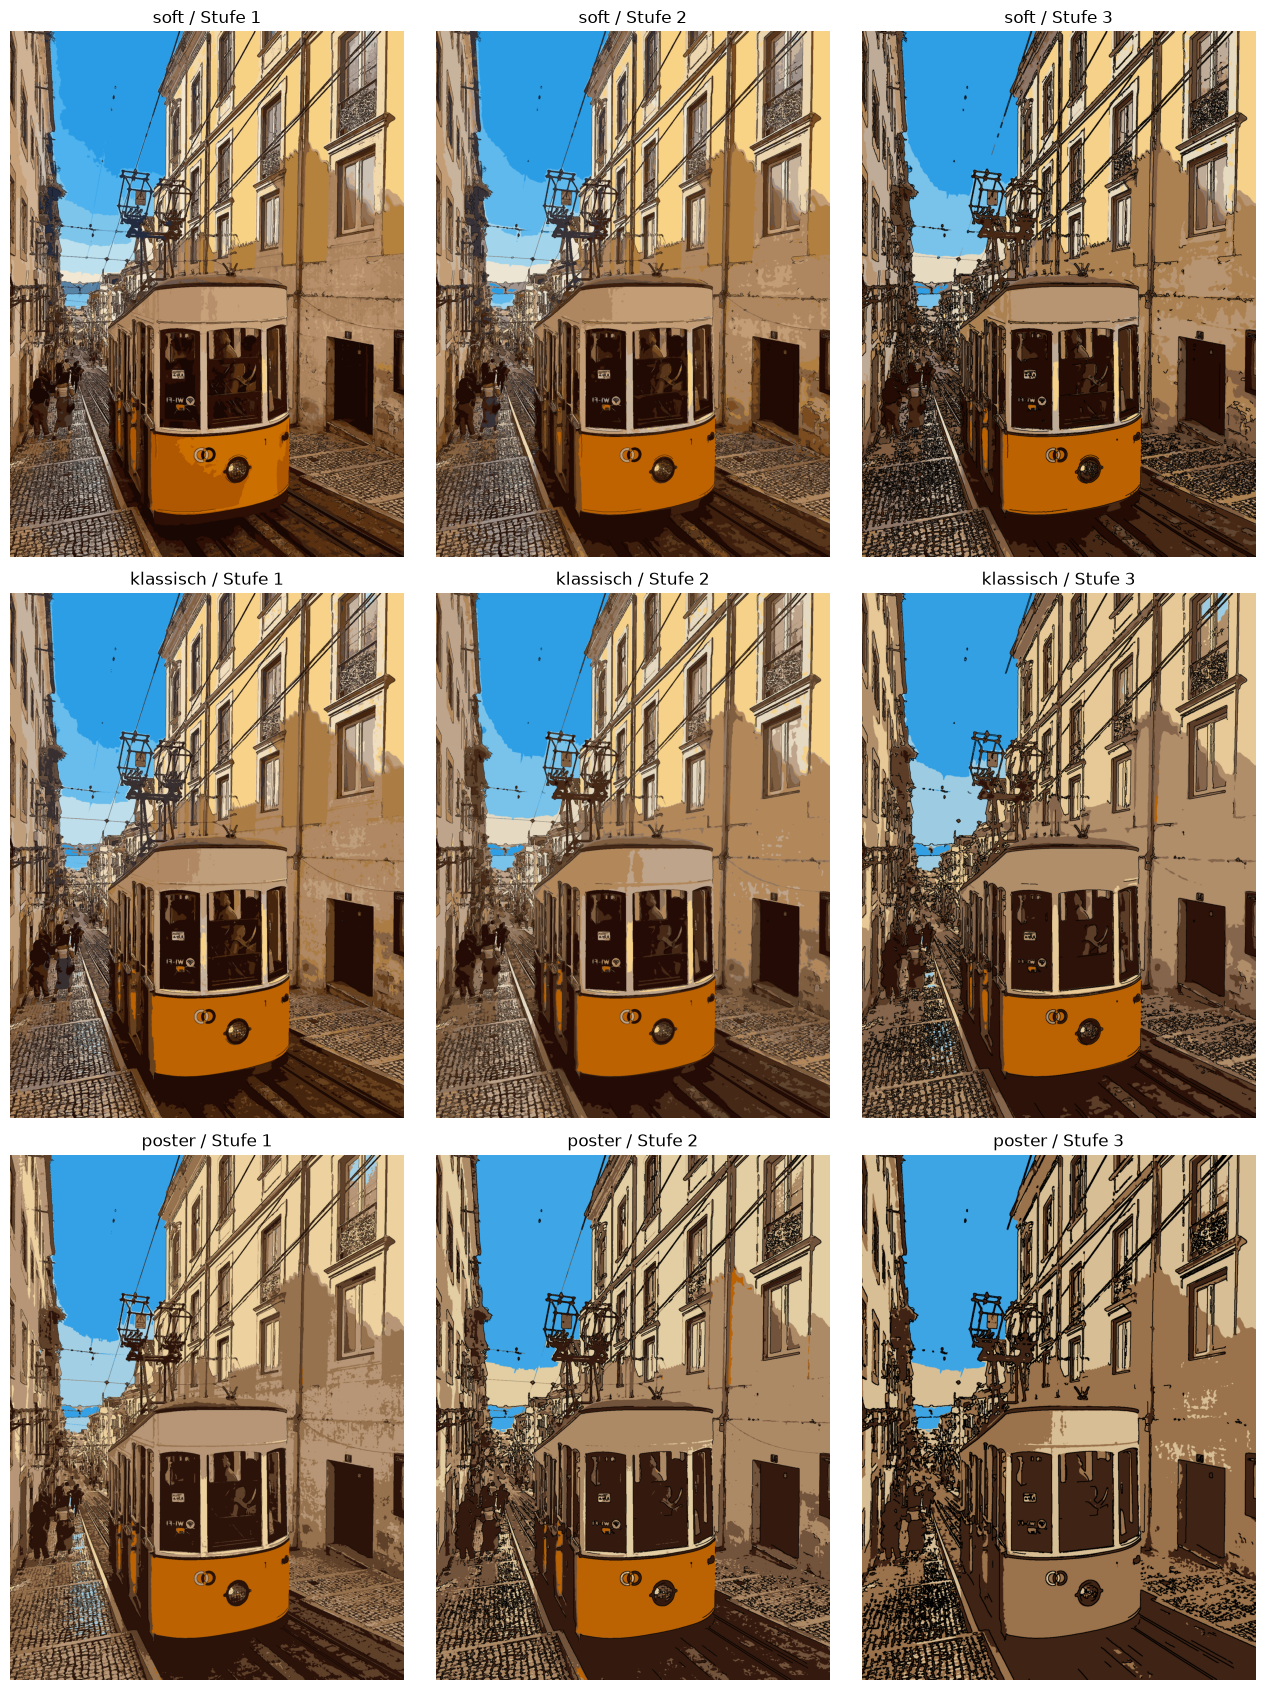

In [22]:
fig, axes = plt.subplots(3, 3, figsize=(13, 17))
for row, style in enumerate(STYLES):
    for col, intensity in enumerate((1, 2, 3)):
        cartoon = cartoonify_style(original, style, intensity)
        axes[row][col].imshow(cv2.cvtColor(cartoon, cv2.COLOR_BGR2RGB))
        axes[row][col].set_title(f"{style} / Stufe {intensity}")
        axes[row][col].axis("off")
fig.tight_layout()
plt.show()

## Personenbild

Zum Abschluss dieselben 9 Stil-/Intensitätskombinationen auf einem Foto mit
Personen – hier zeigen sich die Grenzen der klassischen Pipeline bei
Gesichtern/Hauttönen (k-Means posterisiert Haut schnell fleckig, Canny
reagiert empfindlich auf weiche Gesichtskonturen).

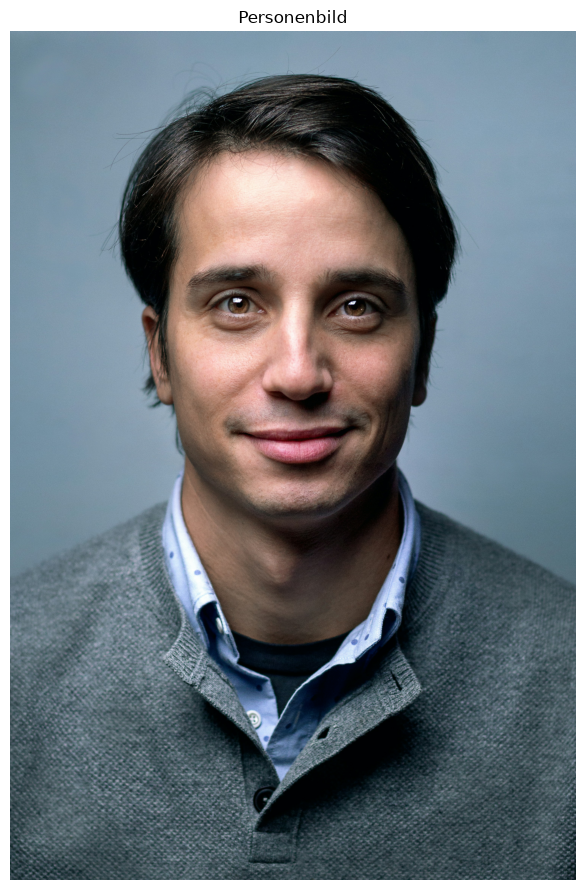

In [23]:
person = cv2.imread("samples/foto_mensch.jpg")
if person is None:
    raise FileNotFoundError("samples/foto_mensch.jpg nicht gefunden.")
show([person], ["Personenbild"], figsize=(7, 9))

In [ ]:
fig, axes = plt.subplots(3, 3, figsize=(13, 17))
for row, style in enumerate(STYLES):
    for col, intensity in enumerate((1, 2, 3)):
        cartoon = cartoonify_style(person, style, intensity)
        axes[row][col].imshow(cv2.cvtColor(cartoon, cv2.COLOR_BGR2RGB))
        axes[row][col].set_title(f"{style} / Stufe {intensity}")
        axes[row][col].axis("off")
fig.tight_layout()
plt.show()

## Fazit und offene Punkte

- **Bilateralfilter** glättet Fassaden und Himmel zuverlässig, ohne die
  groben Gebäudekanten zu verlieren – bei zu vielen Iterationen verschwimmen
  aber feine Details wie die Fahrleitungen.
- **k-Means** liefert den "Cartoon"-Farblook; kleine `k`-Werte wirken schnell
  flach/grafisch (passend für `poster`) und lassen z. B. Fassadenschattierungen
  verschmelzen, große `k`-Werte bleiben natürlicher (passend für `soft`).
- **Kantenerkennung** ist empfindlich gegen die Canny-Schwellenwerte; im
  Testfoto erzeugen die vielen Pflastersteine und Fensterreihen bei niedrigen
  Schwellen zusätzliche Rauschkanten, bei hohen Schwellen gehen feine
  Strukturen (Fahrleitungen, Fensterrahmen) verloren.
- Die drei Stile/Intensitätsstufen decken bereits die geforderte Bandbreite ab.

**Nächste Schritte:** Diese Funktionen dienen als klassische Baseline für den
Verfahrensvergleich in Meilenstein 4 (SSIM/CLIP-I/Content Loss gegen GAN- und
Diffusions-Pipeline) und werden dort in die FastAPI-App übernommen.